# Reunião de acompanhamento (2026-07-30) — diagnóstico e correção de cobertura em z (etapa 6 v2)

Consolidação das tarefas 1-5 combinadas com o orientador (reunião 2026-07-22), reunindo os
achados que sucederam o diagnóstico de cobertura em z. Recapitulando: a calibração original do
bbox por âncora da aorta (etapa 6 v2) produziu um bbox de **480×414×312 voxels** (resolução
integral) e `Rv` de só **~5%** — a cadeia de diagnósticos de 2026-07-22 a 07-27 identificou que
falhas de rastreamento Hough+Level Set (under-/over-tracking da aorta) explicam boa parte disso,
não só variabilidade anatômica real. A partir daí, dois mecanismos de correção foram testados:
**exclusão de casos-outlier** (critérios A/B/C, tarefas 2-4) e **redução percentual direta do
bbox** (tarefa 5, sem excluir casos). Narrativa completa, com todos os números e decisões
intermediárias, em [docs/step6v2_aorta_anchor.md](../docs/step6v2_aorta_anchor.md) — este
notebook não repete esse conteúdo, só reúne os gráficos/tabelas mais relevantes para a conversa.

**Tarefa 6/7 (cruzamento com a lista de falhas de detecção de óstios de Silva/Matheus) segue
bloqueada** — a lista ainda não foi recebida. Não incluída aqui; ver seção 8.

Sem reprocessar nenhuma imagem/máscara: todos os gráficos abaixo reaproveitam CSVs e o cache de
máscaras (voxel a voxel) já gerados nas tarefas anteriores.

In [1]:
# ruff: noqa: E402

import sys
from pathlib import Path

NOTEBOOK_CWD = Path.cwd().resolve()
for candidate in (
    NOTEBOOK_CWD,
    NOTEBOOK_CWD.parent,
    NOTEBOOK_CWD.parent.parent,
):
    src_dir = candidate / "src"
    if src_dir.exists():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break

from utils.project.notebook_env import configure_notebook_environment  # noqa: E402

REPO_ROOT = configure_notebook_environment()
print(f"REPO_ROOT = {REPO_ROOT}")


REPO_ROOT = G:\DAC\heart-bounding-box


In [2]:
import json
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

AORTA_ANCHOR_DIR = REPO_ROOT / "output" / "bounding_box" / "aorta_anchor"
DIAG_DIR = REPO_ROOT / "output" / "bounding_box" / "aorta_anchor_z_diagnosis"
CONFIG_DIR = REPO_ROOT / "config"

EXPECTED_FILES = {
    "all_cases_csv": AORTA_ANCHOR_DIR / "all_cases.csv",
    "splits_json": CONFIG_DIR / "imagecas_splits_train90.json",
    "quintile_csv": DIAG_DIR / "num_circles_quintile_coverage.csv",
    "task4_csv": DIAG_DIR / "task4_exclusion_criterion_evaluation.csv",
    "task5_real_vs_proxy_csv": DIAG_DIR / "task5_percentile_bbox_tradeoff_real_vs_proxy.csv",
    "task5_severe_tail_csv": DIAG_DIR / "task5_severe_tail_case_c5_p95.csv",
    "task7_percase_loss_csv": DIAG_DIR / "task7_percase_real_loss_c5_p95_p100.csv",
}

for label, path in EXPECTED_FILES.items():
    if not path.exists():
        print(f"AVISO: {label} não encontrado em {path} — listando diretório...")
        for candidate in sorted(path.parent.glob("*")):
            print(f"  - {candidate.name}")
        raise FileNotFoundError(
            f"Ajuste o nome esperado para {label}: nenhum arquivo correspondente em {path.parent}"
        )
print("Todos os arquivos esperados existem, nenhum reprocessamento necessário:")
for label, path in EXPECTED_FILES.items():
    print(f"  {label}: {path.relative_to(REPO_ROOT)}")

CALIBRATION_CASES = {934: "y_min", 428: "y_max/x_min", 90: "x_max", 23: "z_min", 44: "z_max"}
WORST_COVERAGE_CASES = [622, 196, 790, 924, 777]
REFERENCE_IMG_ID = 1
REFERENCE_AORTA_VOXELS = 336_651


Todos os arquivos esperados existem, nenhum reprocessamento necessário:
  all_cases_csv: output\bounding_box\aorta_anchor\all_cases.csv
  splits_json: config\imagecas_splits_train90.json
  quintile_csv: output\bounding_box\aorta_anchor_z_diagnosis\num_circles_quintile_coverage.csv
  task4_csv: output\bounding_box\aorta_anchor_z_diagnosis\task4_exclusion_criterion_evaluation.csv
  task5_real_vs_proxy_csv: output\bounding_box\aorta_anchor_z_diagnosis\task5_percentile_bbox_tradeoff_real_vs_proxy.csv
  task5_severe_tail_csv: output\bounding_box\aorta_anchor_z_diagnosis\task5_severe_tail_case_c5_p95.csv
  task7_percase_loss_csv: output\bounding_box\aorta_anchor_z_diagnosis\task7_percase_real_loss_c5_p95_p100.csv


## 2. Falha de cobertura por quintil de `num_circles_detected`

Reaproveita [num_circles_quintile_coverage.csv](../output/bounding_box/aorta_anchor_z_diagnosis/num_circles_quintile_coverage.csv)
(diagnóstico de 2026-07-24) — já usado no notebook de reunião anterior
([reuniao_2026-07-27_diagnostico_z_coverage.ipynb](reuniao_2026-07-27_diagnostico_z_coverage.ipynb));
confirmado que é o mesmo dado, gráfico reaproveitado sem alteração.

In [3]:
quintile_df = pd.read_csv(EXPECTED_FILES["quintile_csv"])
quintile_df


,quintil,num_circles_min,num_circles_max,n,n_fail_y,taxa_fail_y_%,n_fail_x,taxa_fail_x_%,n_fail_z,taxa_fail_z_%
0,1,2.0,83.0,182,12,6.593407,6,3.296703,11,6.043956
1,2,84.0,99.0,186,1,0.537634,1,0.537634,0,0.000000
2,3,100.0,112.0,176,1,0.568182,4,2.272727,0,0.000000
3,4,113.0,130.0,187,0,0.000000,2,1.069519,0,0.000000
4,5,131.0,275.0,175,8,4.571429,3,1.714286,7,4.000000


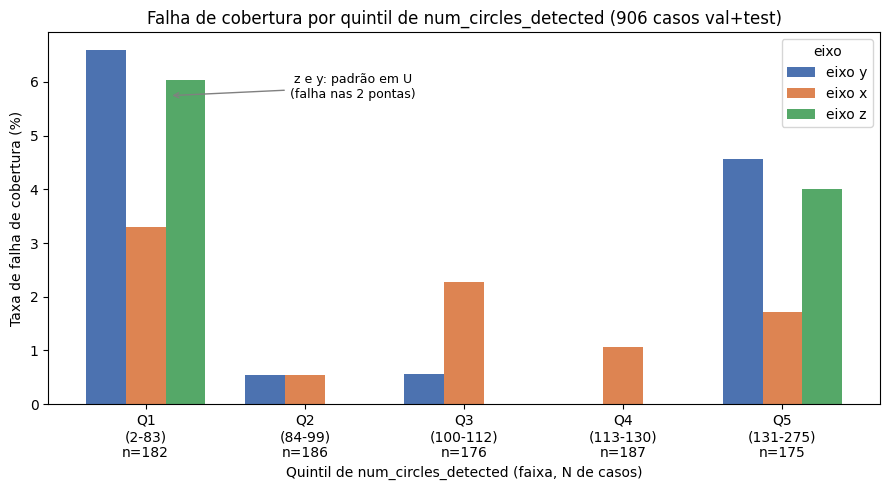

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(quintile_df))
width = 0.25
axes_cols = [
    ("taxa_fail_y_%", "y", "#4C72B0"),
    ("taxa_fail_x_%", "x", "#DD8452"),
    ("taxa_fail_z_%", "z", "#55A868"),
]
for i, (col, label, color) in enumerate(axes_cols):
    ax.bar(x + (i - 1) * width, quintile_df[col], width, label=f"eixo {label}", color=color)

labels = [
    f"Q{row.quintil}\n({row.num_circles_min:.0f}-{row.num_circles_max:.0f})\nn={row.n}"
    for row in quintile_df.itertuples()
]
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlabel("Quintil de num_circles_detected (faixa, N de casos)")
ax.set_ylabel("Taxa de falha de cobertura (%)")
ax.set_title("Falha de cobertura por quintil de num_circles_detected (906 casos val+test)")
ax.legend(title="eixo")
ax.annotate(
    "z e y: padrão em U\n(falha nas 2 pontas)",
    xy=(0.15, quintile_df.loc[0, "taxa_fail_z_%"] - 0.3),
    xytext=(1.3, 5.7),
    fontsize=9,
    ha="center",
    arrowprops=dict(arrowstyle="->", color="gray"),
)
fig.tight_layout()
plt.show()


**Leitura (recapitulando)**: falha de cobertura em z é zero nas 3 faixas centrais de
`num_circles_detected` (quintis 2-4, ~55% dos 906 casos) e concentrada nos dois extremos —
padrão em U, replicado em y, ausente em x (controle). Motivou os critérios de exclusão A
(`num_circles_detected`) e C (`aorta_voxels`) testados a seguir.

## 3. Distribuição de `aorta_voxels` (critério C) e `num_circles_detected` (critério A), com limiares de corte

Histograma dos 994 casos processados (`all_cases.csv`), com os limiares do critério de exclusão
calculados só no split de treino (tarefa 4) marcados como linhas verticais, nos cortes de 5% e
10% de exclusão total. Marcadores no eixo (rug plot) para os 5 casos calibradores da calibração
original, os 5 piores casos de cobertura já inspecionados visualmente, e a referência de
IMG_ID=1.

In [5]:
all_cases = pd.read_csv(EXPECTED_FILES["all_cases_csv"])
ok = all_cases[all_cases["status"] == "ok"]

task4_df = pd.read_csv(EXPECTED_FILES["task4_csv"])


def get_thresholds(criterio_label, exclusion_pct):
    row = task4_df[
        (task4_df["criterio"] == criterio_label) & (task4_df["exclusion_pct"] == exclusion_pct)
    ].iloc[0]
    return float(row["low_threshold"]), float(row["high_threshold"])


thresholds_c = {pct: get_thresholds("C (aorta_voxels)", pct) for pct in (5, 10)}
thresholds_a = {pct: get_thresholds("A (num_circles_detected)", pct) for pct in (5, 10)}
print("Limiares criterio C (aorta_voxels):", thresholds_c)
print("Limiares criterio A (num_circles_detected):", thresholds_a)


Limiares criterio C (aorta_voxels): {5: (103451.6, 675318.0), 10: (118744.6, 524967.8)}
Limiares criterio A (num_circles_detected): {5: (64.3, 171.1), 10: (70.0, 163.9)}


In [6]:
def plot_criterion_histogram(column, thresholds, reference_value, title, xlabel):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(ok[column], bins=60, color="#4C72B0", alpha=0.75, edgecolor="white", linewidth=0.3)

    linestyles = {5: "--", 10: ":"}
    for pct, (low, high) in thresholds.items():
        ax.axvline(low, color="#C44E52", linestyle=linestyles[pct], linewidth=1.5)
        ax.axvline(
            high,
            color="#C44E52",
            linestyle=linestyles[pct],
            linewidth=1.5,
            label=f"limiar {pct}% exclusão",
        )

    y_top = ax.get_ylim()[1]
    rug_y = -0.03 * y_top
    for img_id, axis_label in CALIBRATION_CASES.items():
        val = ok.loc[ok["img_id"] == img_id, column].iloc[0]
        ax.plot(val, rug_y, marker="v", color="#8172B2", markersize=8, clip_on=False)
        ax.annotate(
            str(img_id), (val, rug_y), fontsize=7, ha="center", va="top", color="#8172B2"
        )
    for img_id in WORST_COVERAGE_CASES:
        val = ok.loc[ok["img_id"] == img_id, column].iloc[0]
        ax.plot(val, rug_y * 1.8, marker="v", color="#C44E52", markersize=8, clip_on=False)
        ax.annotate(
            str(img_id), (val, rug_y * 1.8), fontsize=7, ha="center", va="top", color="#C44E52"
        )
    ax.plot(reference_value, rug_y * 2.6, marker="*", color="#55A868", markersize=12, clip_on=False)
    ax.annotate(
        f"ref. IMG_ID={REFERENCE_IMG_ID}",
        (reference_value, rug_y * 2.6),
        fontsize=7,
        ha="center",
        va="top",
        color="#55A868",
    )

    ax.set_ylim(bottom=rug_y * 3.2)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("N de casos (994 processados)")
    handles, labels_ = ax.get_legend_handles_labels()
    by_label = dict(zip(labels_, handles))
    ax.legend(by_label.values(), by_label.keys())
    fig.tight_layout()
    plt.show()


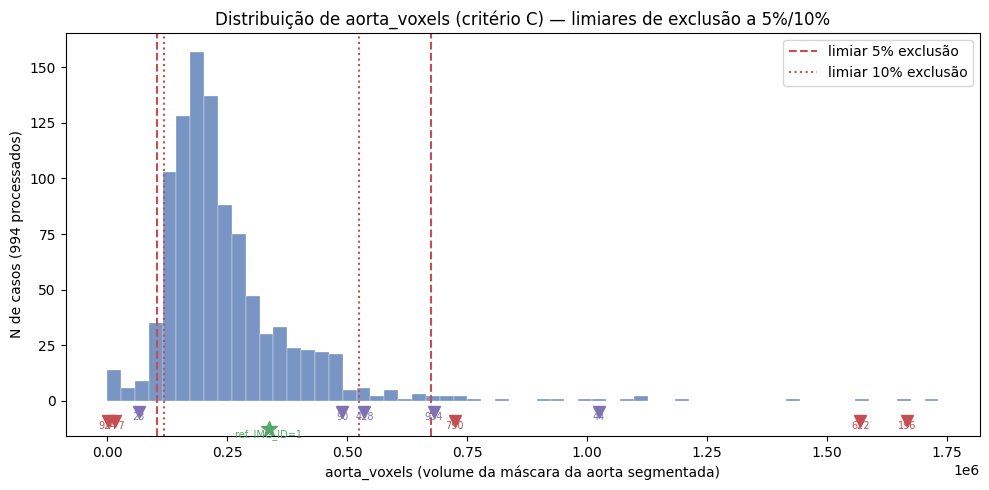

In [7]:
plot_criterion_histogram(
    "aorta_voxels",
    thresholds_c,
    REFERENCE_AORTA_VOXELS,
    "Distribuição de aorta_voxels (critério C) — limiares de exclusão a 5%/10%",
    "aorta_voxels (volume da máscara da aorta segmentada)",
)


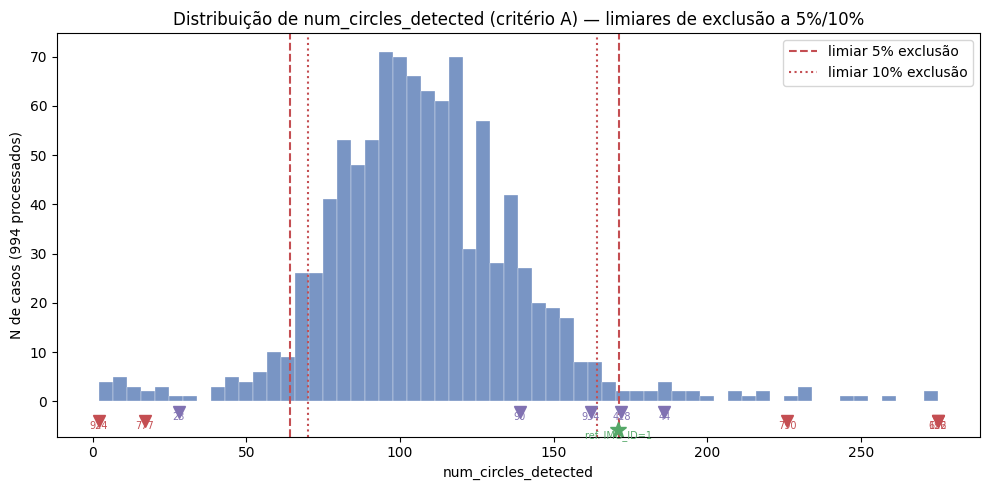

In [8]:
reference_num_circles = float(ok.loc[ok["img_id"] == REFERENCE_IMG_ID, "num_circles_detected"].iloc[0])
plot_criterion_histogram(
    "num_circles_detected",
    thresholds_a,
    reference_num_circles,
    "Distribuição de num_circles_detected (critério A) — limiares de exclusão a 5%/10%",
    "num_circles_detected",
)


**Leitura**: os 5 casos calibradores e os 5 piores casos de cobertura concentram-se nas caudas de
ambas as distribuições (mesmo achado já documentado por percentil na tarefa 3b) — a referência
IMG_ID=1 fica próxima do centro em `aorta_voxels`, mas seu `num_circles_detected` (171) já fica
bem perto do limiar superior de 5% do critério A (171,1) por coincidência, ilustrando por que um
corte marginal pode ser sensível a casos "normais" que ficam perto da borda.

## 4. Distribuição da perda real da árvore coronária (voxel a voxel), por caso

Perda real (não o proxy geométrico de caixa) — voxels do label coronário fora do bbox dividido
pelo total de voxels do label daquele caso — para o ponto recomendado (`arm` = "com filtro
critério C 5%", `offset_percentile=95`) contra o baseline sem redução percentual
(`offset_percentile=100`, mesmo arm). Reconstruído a partir do cache de máscaras já gerado
(`label_voxel_cache_valtest.pkl`), sem reler nenhum NIfTI — dados por caso salvos em
[task7_percase_real_loss_c5_p95_p100.csv](../output/bounding_box/aorta_anchor_z_diagnosis/task7_percase_real_loss_c5_p95_p100.csv).

In [9]:
percase_loss_df = pd.read_csv(EXPECTED_FILES["task7_percase_loss_csv"])
percase_loss_df.head()


,img_id,split,arm,offset_percentile,loss_fraction,loss_pct
0,1,test,com filtro criterio C 5%,95.0,0.000000,0.000000
1,3,test,com filtro criterio C 5%,95.0,0.019483,1.948325
2,4,test,com filtro criterio C 5%,95.0,0.009359,0.935860
3,5,test,com filtro criterio C 5%,95.0,0.145402,14.540166
4,6,val,com filtro criterio C 5%,95.0,0.000000,0.000000


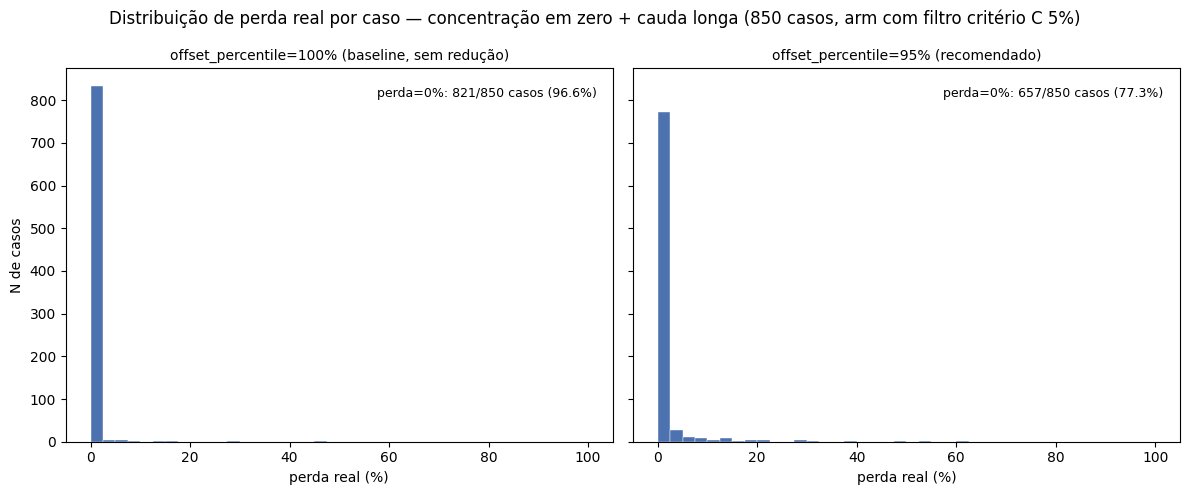

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
levels = [(100.0, "offset_percentile=100% (baseline, sem redução)"), (95.0, "offset_percentile=95% (recomendado)")]
bins = np.linspace(0, 100, 41)

for ax, (level, title) in zip(axes, levels):
    sub = percase_loss_df[percase_loss_df["offset_percentile"] == level]
    ax.hist(sub["loss_pct"], bins=bins, color="#4C72B0", edgecolor="white", linewidth=0.3)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("perda real (%)")
    n_zero = int((sub["loss_pct"] <= 1e-9).sum())
    ax.annotate(
        f"perda=0%: {n_zero}/{len(sub)} casos ({100*n_zero/len(sub):.1f}%)",
        xy=(0.97, 0.95),
        xycoords="axes fraction",
        ha="right",
        va="top",
        fontsize=9,
    )

axes[0].set_ylabel("N de casos")
fig.suptitle("Distribuição de perda real por caso — concentração em zero + cauda longa (850 casos, arm com filtro critério C 5%)")
fig.tight_layout()
plt.show()


**Leitura**: em ambos os níveis, a distribuição concentra-se fortemente em perda zero (821/850 em
100%; 657/850 em 95%), com uma cauda longa de casos com perda maior — o eixo y comprimido pela
concentração em zero dificulta ver a cauda no histograma linear; a tabela de faixas (seção 6 e
`docs/step6v2_aorta_anchor.md`) quantifica essa cauda em detalhe.

## 5. `Rv` × percentil do bbox — duas curvas (com e sem filtro do critério C)

Não é histograma, mas é o resultado mais decisório da investigação. `Rv` médio (redução
volumétrica) por nível de `offset_percentile`, comparando a grade sem filtro de caso (reteste
direto de 2026-07-17) com a grade filtrada previamente pelo critério C a 5%.

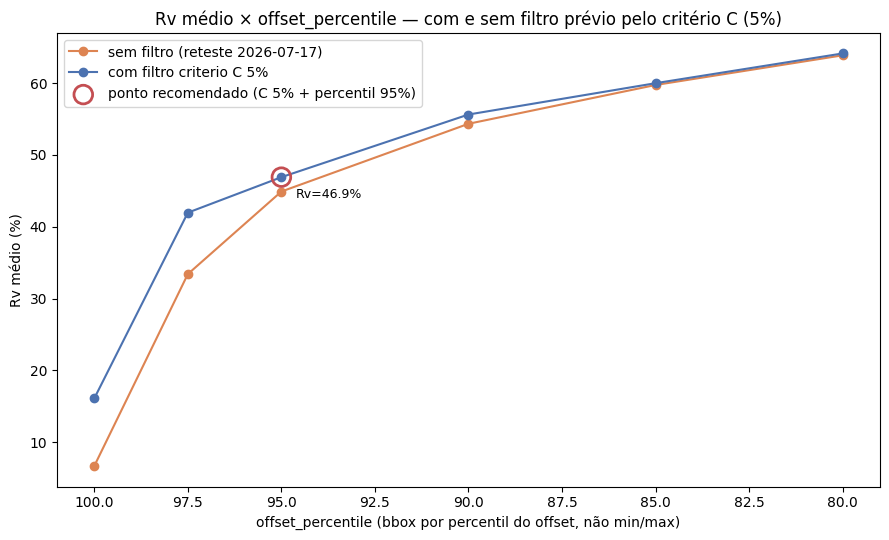

In [11]:
tradeoff_df = pd.read_csv(EXPECTED_FILES["task5_real_vs_proxy_csv"])

fig, ax = plt.subplots(figsize=(9, 5.5))
arm_colors = {
    "sem filtro (reteste 2026-07-17)": "#DD8452",
    "com filtro criterio C 5%": "#4C72B0",
}
for arm, color in arm_colors.items():
    sub = tradeoff_df[tradeoff_df["arm"] == arm].sort_values("offset_percentile")
    ax.plot(sub["offset_percentile"], sub["rv_mean_%"], marker="o", color=color, label=arm)

recommended = tradeoff_df[
    (tradeoff_df["arm"] == "com filtro criterio C 5%") & (tradeoff_df["offset_percentile"] == 95.0)
].iloc[0]
ax.scatter(
    [recommended["offset_percentile"]],
    [recommended["rv_mean_%"]],
    s=180,
    facecolors="none",
    edgecolors="#C44E52",
    linewidths=2,
    zorder=5,
    label="ponto recomendado (C 5% + percentil 95%)",
)
ax.annotate(
    f"Rv={recommended['rv_mean_%']:.1f}%",
    xy=(recommended["offset_percentile"], recommended["rv_mean_%"]),
    xytext=(10, -15),
    textcoords="offset points",
    fontsize=9,
)

ax.set_xlabel("offset_percentile (bbox por percentil do offset, não min/max)")
ax.set_ylabel("Rv médio (%)")
ax.set_title("Rv médio × offset_percentile — com e sem filtro prévio pelo critério C (5%)")
ax.invert_xaxis()
ax.legend()
fig.tight_layout()
plt.show()


**Leitura**: as duas curvas têm formato parecido — `Rv` cresce rápido ao sair de 100% (mínimo/
máximo absoluto) e desacelera a partir de ~90%. O filtro prévio (linha azul) fica sistematicamente
acima da sem filtro (laranja) em todo o intervalo — remover outliers de segmentação antes ajuda o
`Rv` em qualquer nível de percentil, não só no ponto recomendado.

## 6. Os 13 casos da cauda severa no ponto recomendado (critério C 5% + `offset_percentile=95%`)

Tabela simples (sem gráfico) — os 13 `img_id` com perda real ≥20% neste ponto específico,
já identificados no fechamento da tarefa 5. Nenhum coincide com os 5 casos calibradores originais
nem com os 5 piores casos de cobertura já inspecionados visualmente — todos são casos novos, não
caracterizados por nenhum diagnóstico anterior.

In [12]:
severe_df = pd.read_csv(EXPECTED_FILES["task5_severe_tail_csv"]).sort_values(
    "loss_pct", ascending=False
).reset_index(drop=True)

# Classificação por proximidade do limiar do critério C a 5% (ver docs/step6v2_aorta_anchor.md,
# fechamento da tarefa 5, para os valores de margem calculados por caso).
NEAR_THRESHOLD_IDS = {132, 246, 601, 976, 554}
severe_df["classificacao"] = severe_df["img_id"].apply(
    lambda i: "perto do limiar do critério C" if i in NEAR_THRESHOLD_IDS else "não-caracterizado"
)
severe_df


,img_id,loss_pct,split,classificacao
0,132,61.212997,test,perto do limiar do critério C
1,191,53.202598,test,não-caracterizado
2,601,49.858664,test,perto do limiar do critério C
3,941,47.622825,test,não-caracterizado
4,754,39.365572,test,não-caracterizado
5,321,37.823195,test,não-caracterizado
6,976,30.861892,test,perto do limiar do critério C
7,499,29.948282,test,não-caracterizado
8,554,28.300642,test,perto do limiar do critério C
9,529,27.966836,test,não-caracterizado


**Registro explícito**: 5 dos 13 (132, 246, 601, 976, 554) ficam perto da borda do limiar do
critério C a 5% — candidatos a serem capturados com um corte um pouco mais agressivo (7-10%). Os
**outros 8-9 casos não são explicados por nenhum critério de qualidade de segmentação testado**
(`aorta_voxels` e `num_circles_detected` "normais" para esses casos) — candidatos a
variabilidade anatômica real, não artefato de segmentação, ou a um mecanismo de falha ainda não
identificado. Não caracterizados além disso aqui.

## 7. Timeline de hipóteses testadas

Resumo de todas as hipóteses mecanísticas e critérios de correção testados desde o achado
bloqueante original, sem repetir o texto completo de cada seção correspondente em
[docs/step6v2_aorta_anchor.md](../docs/step6v2_aorta_anchor.md).

In [13]:
timeline_rows = [
    {
        "hipótese": "Trocar componente z da âncora: centróide -> z_min (proximal/raiz)",
        "teste": "Amostra estratificada de 50 casos; dispersão do offset (std, amplitude)",
        "resultado": "Dispersão em z piorou (std -23% a -28%, amplitude -49% a -63%) em vez de melhorar",
        "status": "descartada",
    },
    {
        "hipótese": "'Colar na borda do FOV' é artefato/sinal dos casos-problema",
        "teste": "Prevalência em amostra de 50 casos + leitura do código-fonte + inspeção HU bruta",
        "resultado": "Universal por desenho do algoritmo (100% em ambos os grupos); anatomia real e coerente",
        "status": "descartada como fator discriminante",
    },
    {
        "hipótese": "Ambiguidade de vasos no desfiladeiro torácico explica leak/truncamento",
        "teste": "Métrica objetiva (raio ±20%, distância <2x raio médio), 10 casos-problema + 30 normais",
        "resultado": "Distribuições quase totalmente sobrepostas - provável efeito-teto nos limiares",
        "status": "inconclusiva",
    },
    {
        "hipótese": "Critério de exclusão A: percentil de num_circles_detected",
        "teste": "Recalibração + cobertura sobre subconjunto filtrado, grade 5-20% (tarefa 2/4)",
        "resultado": "A 10%: Rv~19,3%, captura 4/5 calibradores; caso 90 nunca capturado até 20%",
        "status": "testada",
    },
    {
        "hipótese": "Critério de exclusão B: percentil de envelope_extent (usa o label)",
        "teste": "Recalibração + cobertura sobre subconjunto filtrado (tarefa 3)",
        "resultado": "Depende do label coronário - só serve como curadoria de dataset, não pipeline",
        "status": "reclassificada (não elegível para produção)",
    },
    {
        "hipótese": "Critério de exclusão C: percentil de aorta_voxels (label-free)",
        "teste": "Recalibração + cobertura sobre subconjunto filtrado, grade 5-20% (tarefa 3b/4)",
        "resultado": "Primeiro a capturar os 5 calibradores simultaneamente (10%); Jaccard(A,C)=0,52 vs. Jaccard(*,B)~0,07",
        "status": "testada, melhor candidato label-free até aqui",
    },
    {
        "hipótese": "Redução percentual direta do bbox (sem excluir casos)",
        "teste": "Reteste de 2026-07-17 com perda parcial REAL (voxel a voxel) em vez de cobertura binária (tarefa 5)",
        "resultado": "Meio-termo bem mais favorável que a métrica binária sugeria para o grosso dos casos; mas o proxy geométrico SUBESTIMA a cauda severa (>=20%) nos cortes mais agressivos",
        "status": "achado revisado - aponta para critério C 5% + percentil 95% como ponto de discussão",
    },
]
timeline_df = pd.DataFrame(timeline_rows)
timeline_df


,hipótese,teste,resultado,status
0,Trocar componente z da âncora: centróide -> z_...,Amostra estratificada de 50 casos; dispersão d...,"Dispersão em z piorou (std -23% a -28%, amplit...",descartada
1,'Colar na borda do FOV' é artefato/sinal dos c...,Prevalência em amostra de 50 casos + leitura d...,Universal por desenho do algoritmo (100% em am...,descartada como fator discriminante
2,Ambiguidade de vasos no desfiladeiro torácico ...,"Métrica objetiva (raio ±20%, distância <2x rai...",Distribuições quase totalmente sobrepostas - p...,inconclusiva
3,Critério de exclusão A: percentil de num_circl...,Recalibração + cobertura sobre subconjunto fil...,"A 10%: Rv~19,3%, captura 4/5 calibradores; cas...",testada
4,Critério de exclusão B: percentil de envelope_...,Recalibração + cobertura sobre subconjunto fil...,Depende do label coronário - só serve como cur...,reclassificada (não elegível para produção)
5,Critério de exclusão C: percentil de aorta_vox...,Recalibração + cobertura sobre subconjunto fil...,Primeiro a capturar os 5 calibradores simultan...,"testada, melhor candidato label-free até aqui"
6,Redução percentual direta do bbox (sem excluir...,Reteste de 2026-07-17 com perda parcial REAL (...,Meio-termo bem mais favorável que a métrica bi...,achado revisado - aponta para critério C 5% + ...


## 8. Recomendação para discussão e pendências em aberto

**Ponto de discussão (não é uma decisão fechada)**: critério de exclusão C (5% de exclusão total,
`aorta_voxels`) combinado com bbox por percentil 95% (não min/max) —
`Rv` médio ≈ 46,9%, perda mediana real 0%, ~1,5% dos casos (13 de 850) com perda severa (≥20% da
árvore), dos quais 8-9 não explicados por nenhum critério de qualidade de segmentação testado até
aqui.

**Pendências explícitas, sem recomendar resposta — decisão do Hélder com o orientador:**

1. **Tarefa 6/7 segue bloqueada**: falta a lista de falhas de detecção de óstios de Silva/Matheus
   para cruzar com os casos-problema já identificados aqui.
2. **8-9 casos residuais da cauda severa não caracterizados** (seção 6) — candidatos a inspeção
   visual futura, sem hipótese mecanística testada até aqui.
3. **Revisão textual da qualificação sobre a validação do LCC** (achado de 2026-07-17, já
   documentado em `docs/step6v2_aorta_anchor.md` — o texto afirma isolamento consistente do
   coração pelo LCC, contrariado empiricamente) — pendente, independente de toda a investigação de
   cobertura em z acima.

Este notebook não decide qual critério/corte adotar — é material de apoio para a conversa com o
orientador; a decisão sobre os próximos passos é do Hélder.